# project 4

In [2]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import re
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import copy
from collections import defaultdict

In [7]:
# import pandas as pd

# BASE = "https://raw.githubusercontent.com/mathbeveridge/asoiaf/master/data"

# edges = pd.read_csv(f"{BASE}/asoiaf-all-edges.csv")
# nodes = pd.read_csv(f"{BASE}/asoiaf-all-nodes.csv")

# # print(edges.head())
# # print(nodes.head())
# print(f"Edges: {len(edges)}, Nodes: {len(nodes)}")

degrees = (np.random.default_rng(0).pareto(1.5, 100000) + 1).astype(int)

In [8]:
if degrees.sum() % 2:
    degrees[0] += 1

G = nx.Graph(nx.configuration_model(degrees, seed=0))
G.remove_edges_from(nx.selfloop_edges(G))

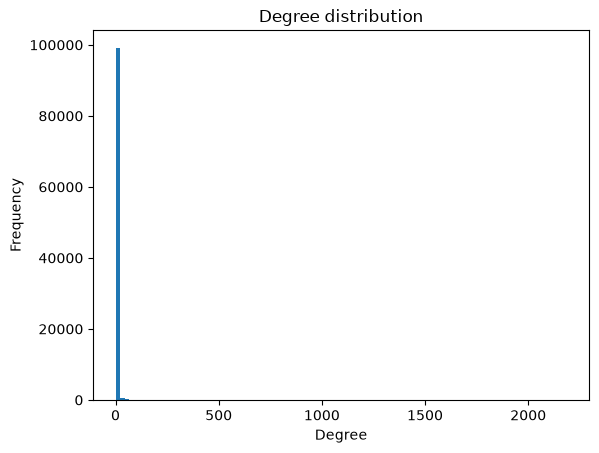

In [9]:
# plt.figure(figsize=(14, 10))
degrees = [d for _, d in G.degree()] # without the weights
plt.hist(degrees, bins=100)
plt.title("Degree distribution")
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.show()

double logarithmic scale

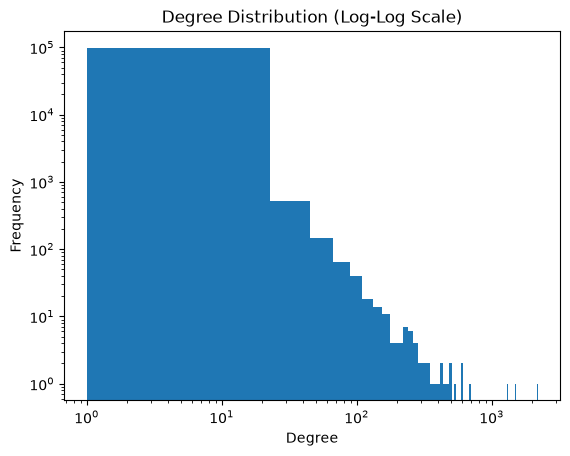

In [15]:
degrees = [d for _, d in G.degree()] # without the    weights
# degrees1p = np.log1p(degrees)
plt.hist(degrees, bins=100)
plt.title("Degree Distribution (Log-Log Scale)")
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.xscale("log")
plt.yscale("log")
plt.show()

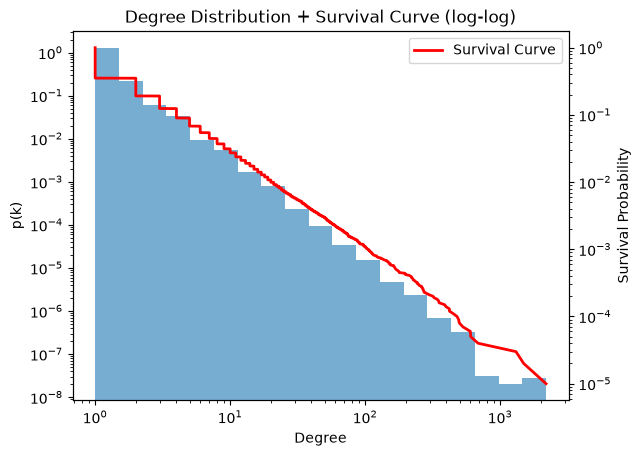

In [19]:
degrees = np.array([d for _, d in G.degree() if d > 0])

# histogram
bins = np.logspace(0, np.log10(degrees.max()), 20)
plt.hist(degrees, bins=bins, density=True, alpha=0.6, label="Frequency Histogram")
plt.title("Degree Distribution + Survival Curve (log-log)")
plt.xlabel("Degree")
plt.ylabel("p(k)")
plt.xscale("log")
plt.yscale("log")

# survival function
sorted_degrees = np.sort(degrees)
survival_prob = 1.0 - (np.arange(len(sorted_degrees)) / float(len(sorted_degrees)))

# second axis
ax2 = plt.gca().twinx()
ax2.plot(sorted_degrees, survival_prob, color="red", linewidth=2, label="Survival Curve")
ax2.set_ylabel("Survival Probability")
ax2.set_yscale("log")

lines_1, labels_1 = plt.gca().get_legend_handles_labels()

ax2.legend(lines_1, labels_1, loc="upper right")
plt.show()

The least readable chart is the normal axis histogram. Some values from the long tail are almost not visible compared to the high counts of low degree values. The only advantage might be the normal axes to show the general shape of the data for people not used to the logarithmic scale. Although with this alpha it does not make sense. </br></br>
The log log scale plot without the logarithmic binning has better readability. However, the fact that on the left side bins are wide and on the right are narrow lowers the noise values readability on the right.</br></br>
The logarithmic binning is the most robust out of all. The survival function adds the details lost in the process of logarithmic binning in the noise values. Both follow a straight line on the log log scale, which confirms the power law. This makes the last plot robust.

### alpha estimation

In [20]:
degrees = [d for _, d in G.degree()]
len([d for d in degrees if d <1])

0

In [21]:
degrees = np.array([d for _, d in G.degree()], dtype=float)

bins = np.logspace(np.log10(degrees.min()), np.log10(degrees.max()), 20)
hist, edges = np.histogram(degrees, bins=bins)
# print(edges)
centers = np.sqrt(edges[:-1] * edges[1:])
# print(centers)
widths = edges[1:] - edges[:-1]
pdf = hist / (hist.sum() * widths)
# only positive values to get the correct slope
mask = pdf > 0
x = np.log10(centers[mask])
y = np.log10(pdf[mask])
slope, intercept = np.polyfit(x, y, 1)
alpha_pdf = -slope
print(f"Estimated alpha: {alpha_pdf}")

Estimated alpha: 2.4495963416202695


### alpha MLE estimator
$$ \hat{\alpha} = 1 + \frac{n}{\sum_{i=1}^{n} \ln\left(\frac{x_i}{x_{min}}\right)} $$


In [22]:
degrees = np.array([d for _, d in G.degree()], dtype=float)
xmin = 1

x = degrees[degrees >= xmin]
n = len(x)
alpha_mle = 1 + n / np.sum(np.log(x / xmin))
print(f"Estimated alpha: {alpha_mle}")

Estimated alpha: 3.3114371863475722


The true alpha is 2.5. The regression line is a good estimator. THe MLE estimator is off. This happens, as a lot of numbers from 1-2 are cut to 1. This interval is huge respectively to xmin value. A lot of values fall into it thus in MLE estimator a lot of values are equal 0 in the log(x/xmin) part. This is driving the alpha to higher values.

How will the result change if we do not know xmin?

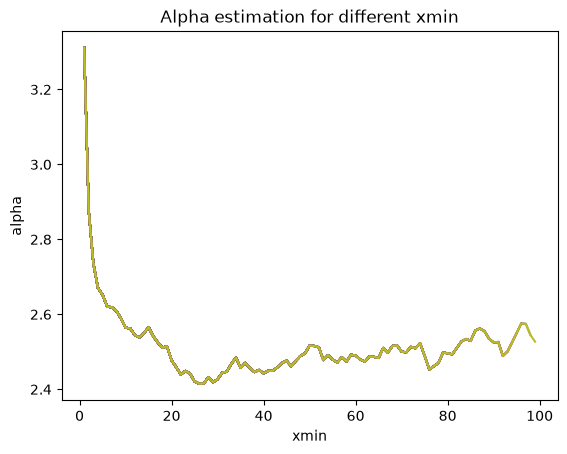

In [25]:
xmins = []
for i in range(1, 100):
    xmins.append(i)
    alphas = []
    for xmin in xmins:
        x = degrees[degrees >= xmin]
        n = len(x)
        alpha_mle = 1 + n / np.sum(np.log(x / xmin))
        alphas.append(alpha_mle)
    plt.plot(xmins, alphas)
plt.title("Alpha estimation for different xmin")
plt.xlabel("xmin")
plt.ylabel("alpha")
plt.show()



Without the xmin we can estimate the alpha at around the true 2.5 value from this plot. It is where the alpha becomes stabler. We can also try to estimate the xmin value from the MLE estimator.

$$\hat{x}_{min} =  min_ix_i $$

In our data it will be 1. Which after alpha calculations will return the same value as the previous ones.

In [28]:
mle_xmin = np.min(degrees)
print(f"Estimated xmin: {mle_xmin}")

Estimated xmin: 1.0


## p4.3 + p4.4 + p4.6
data:</br>
https://public.websites.umich.edu/~mejn/netdata/

</br>
Astrophysics collaborations: M. E. J. Newman, Proc. Natl. Acad. Sci. USA 98, 404-409 (2001).

Condensed matter collaborations 2005: M. E. J. Newman, Proc. Natl. Acad. Sci. USA 98, 404-409 (2001).

Internet: Mark Newman, University of Oregon Route Views Project, 22 lipca 2006.

In [31]:
graphs = {
    d.name: nx.read_gml(d / f"{d.name}.gml", label="id")
    for d in sorted(Path("data").iterdir())
    if d.is_dir()
}
for name, G in graphs.items():
    print(name, G.number_of_nodes(), G.number_of_edges())

as-22july06 22963 48436
astro-ph 16706 121251
cond-mat-2005 40421 175692


In [40]:
for name, G in graphs.items():
    print(f"{name}: {2 * G.number_of_edges() / G.number_of_nodes():.2f}")

as-22july06: 4.22
astro-ph: 14.52
cond-mat-2005: 8.69


In [33]:
def knn_of_k(H):
    deg = dict(H.degree())
    ann = {
        n: np.mean([deg[nbr] for nbr in H.neighbors(n)])
        for n in H if deg[n] > 0
    }
    buckets = defaultdict(list)
    for n, k in deg.items():
        if k > 0:
            buckets[k].append(ann[n])
    ks = np.array(sorted(buckets))
    vals = np.array([np.mean(buckets[k]) for k in ks])
    return ks, vals

as-22july06


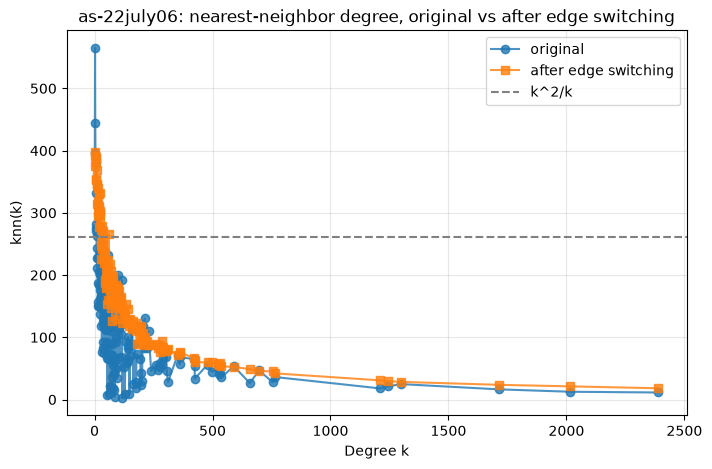

astro-ph


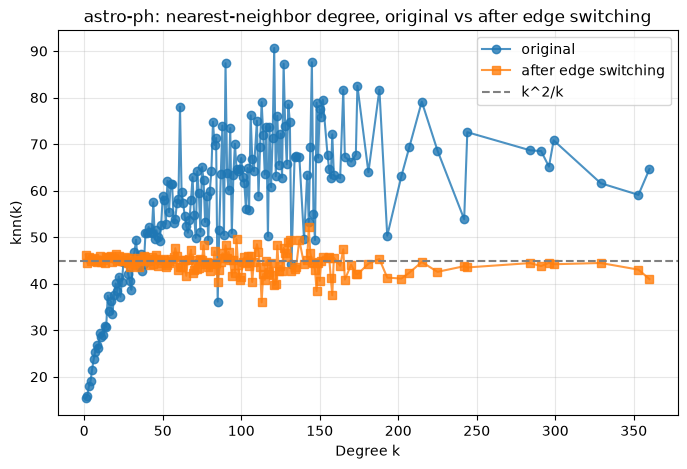

cond-mat-2005


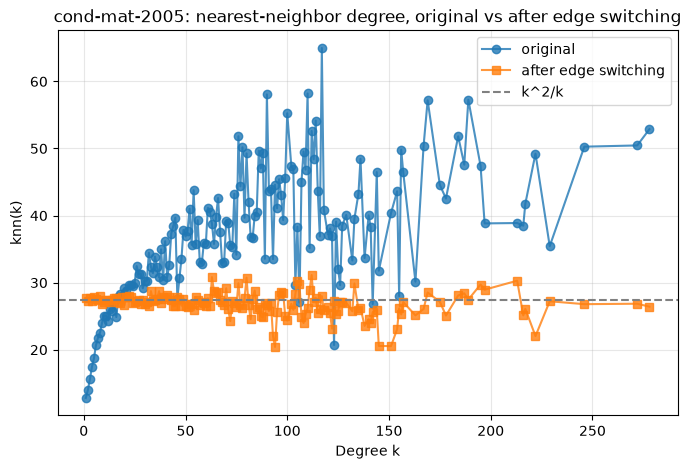

In [37]:
for name, G in graphs.items():
    # baseline
    ks0, knn0 = knn_of_k(G)

    # degree-preserving random switching
    G_switch = G.copy()
    n_swaps = int(np.max([10, np.log(G_switch.number_of_edges())]) * G_switch.number_of_edges()) # log(E) * E
    nx.double_edge_swap(G_switch, nswap=n_swaps, max_tries=n_swaps * 10)

    ks1, knn1 = knn_of_k(G_switch)

    # same degree sequence?
    print(name)
    # print("degrees equal:", sorted(d for _, d in G.degree()) == sorted(d for _, d in G_switch.degree()))
    # print(f"correlation coefficient before: {nx.degree_assortativity_coefficient(G):.3f}")
    # print(f"correlation coefficient after: {nx.degree_assortativity_coefficient(G_switch):.3f}")

    plt.figure(figsize=(8, 5))
    plt.plot(ks0, knn0, "o-", label="original", alpha=0.8)
    plt.plot(ks1, knn1, "s-", label="after edge switching", alpha=0.8)

    # uncorrelated baseline from P4.2
    degrees = np.array([d for _, d in G.degree()], dtype=float)
    k_nn_uncorr = np.mean(degrees**2) / np.mean(degrees)
    plt.axhline(k_nn_uncorr, color="gray", linestyle="--", label="k^2/k")

    plt.xlabel("Degree k")
    plt.ylabel("knn(k)")
    plt.title(f"{name}: nearest-neighbor degree, original vs after edge switching")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [46]:
G = graphs["as-22july06"]
deg = np.array([d for _, d in G.degree()])
k_s = np.sqrt(deg.mean() * len(deg))
print(f"degree cutoff: {k_s}")
print(f"fraction of nodes over degree cutoff: {np.mean(deg > k_s):.4f}")
print(f"number of nodes over degree cutoff: {np.sum(deg > k_s)}")

degree cutoff: 311.24267059643347
fraction of nodes over degree cutoff: 0.0010
number of nodes over degree cutoff: 23


For the last two graphs (astro-ph and cond-mat-2005) the edge switching worked very well. After switching knn(k) is flat and close to the uncorrelated baseline k^2/k, so the original degree correlations were removed.

For the first graph (as-22july06) the shape stays almost the same after switching. This comes from the structure of the network. The largest degree (2390) is much bigger thatn the stucture cutoff ($\sqrt{N<k>} = 312$). In a simple graph two nodes cannot share more than one edge, so the hubs cannot connect to each other as often as a random graph would require. They are forced to connect mostly to low-degree nodes, so the network stays disassortative even after random rewiring.

In [38]:
def assortativity(G):
    deg = dict(G.degree())
    j = np.array([deg[u] for u, v in G.edges()], dtype=float)
    k = np.array([deg[v] for u, v in G.edges()], dtype=float)
    mean = np.mean(0.5 * (j + k))
    num = np.mean(j * k) - mean**2
    den = np.mean(0.5 * (j**2 + k**2)) - mean**2
    return num / den

In [39]:
rows = []
for name, G in graphs.items():
    G_switch = G.copy()
    n_swaps = int(np.max([10, np.log(G_switch.number_of_edges())]) * G_switch.number_of_edges())
    nx.double_edge_swap(G_switch, nswap=n_swaps, max_tries=n_swaps * 10, seed=0)
    rows.append({
        "graph": name,
        "r before": assortativity(G),
        "r after": assortativity(G_switch),
    })

pd.DataFrame(rows).set_index("graph").round(3)

,r before,r after
graph,,
as-22july06,-0.198,-0.187
astro-ph,0.235,-0.008
cond-mat-2005,0.186,-0.001


The values confirm what we saw on the knn(k) plots. For astro-ph and cond-mat-2005 the networks are clearly assortative before switching, and after rewiring the coefficient drops to almost exactly 0, so the degree correlations were fully removed. For as-22july06 the coefficient barely changes (−0.198 → −0.187). The network stays disassortative even after random rewiring, which confirms that this disassortativity is structural.

## P4.7

data from https://sites.google.com/oakland.edu/grossman/home/the-erdoes-number-project?pli=1&authuser=0 </br>
Definition
- Paul Erdős has Erdős number equal to 0.
- Erdős number of every scientists is equal to minimum of the
Erdős numbers of his/her coauthors +1.

In [71]:
from pathlib import Path

nobel = pd.read_csv(Path("data/nobel.txt"), sep=";")
fields = pd.read_csv(Path("data/fields.txt"), sep=";")

nobel["erdos"] = pd.to_numeric(nobel["erdos"], errors="coerce")
fields["erdos"] = pd.to_numeric(fields["erdos"], errors="coerce")

nobel = nobel.dropna(subset=["erdos"]).astype({"year": int, "erdos": int})
fields = fields.dropna(subset=["erdos"]).astype({"year": int, "erdos": int})

display(nobel.head(), fields.head())

,name,year,subject,erdos
0,Hendrik Lorentz,1902,Physics,3
1,Pieter Zeeman,1902,Physics,4
2,Antoine Henri Becquerel,1903,Physics,5
3,Pierre Curie,1903,Physics,8
4,Marie Curie,1903,Physics,7


,name,year,country,erdos
0,Lars Ahlfors,1936,Finland,4
1,Jesse Douglas,1936,USA,4
2,Laurent Schwartz,1950,France,4
3,Atle Selberg,1950,Norway,2
4,Kunihiko Kodaira,1954,Japan,2


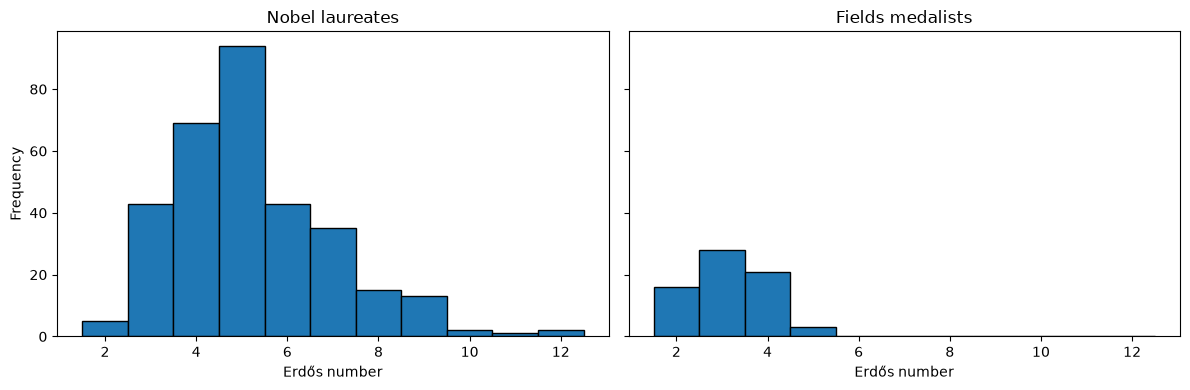

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
# nobel["erdos"] = nobel["erdos"].astype(int)
# fields["erdos"] = fields["erdos"].astype(int)

max_erdos = max(nobel["erdos"].max(), fields["erdos"].max())
bins_nobel = range(int(nobel["erdos"].min()), int(max_erdos) + 2)
bins_fields = range(int(fields["erdos"].min()), int(max_erdos) + 2)

axes[0].hist(nobel["erdos"], bins=bins_nobel, edgecolor="black", align="left")
axes[0].set_title("Nobel laureates")
axes[0].set_xlabel("Erdős number")
axes[0].set_ylabel("Frequency")

axes[1].hist(fields["erdos"], bins=bins_fields, edgecolor="black", align="left")
axes[1].set_title("Fields medalists")
axes[1].set_xlabel("Erdős number")

plt.tight_layout()
plt.show()

Bacon number https://oracleofbacon.org/center.php </br>
oscar winners https://www.kaggle.com/datasets/unanimad/the-oscar-award

In [ ]:
import requests

YEAR_MIN, YEAR_MAX = 1900, 1980
SLEEP_SEC = 1.0
OUT_PATH = Path("data/oscar_bacon_1940_1980.txt")

df = pd.read_csv(Path("data/the_oscar_award.csv"))
winners = df[df["winner"] == True].copy()
winners = winners[
    (winners["year_ceremony"] >= YEAR_MIN)
    & (winners["year_ceremony"] <= YEAR_MAX)
]
winners = winners[
    winners["category"].astype(str).str.contains(r"ACTOR|ACTRESS", case=False)
]
winners["name"] = winners["name"].astype(str).str.strip()

people = (
    winners.sort_values("year_ceremony")
    .drop_duplicates(subset=["name"])
    [["name", "year_ceremony", "category", "film"]]
    .reset_index(drop=True)
)
print(f"Unique acting Oscar winners {YEAR_MIN}-{YEAR_MAX}: {len(people)}")
people.head()

Unique acting Oscar winners 1900-1980: 169


,name,year_ceremony,category,film
0,Emil Jannings,1928,ACTOR,The Last Command
1,Janet Gaynor,1928,ACTRESS,7th Heaven
2,Warner Baxter,1929,ACTOR,In Old Arizona
3,Mary Pickford,1929,ACTRESS,Coquette
4,George Arliss,1930,ACTOR,Disraeli


In [83]:
import time
def bacon_number(actor: str, session: requests.Session) -> str:
    r = session.post(
        "https://www.oracleofbacon.org/movielinks.php",
        data={
            "a": actor,
            "b": "Kevin Bacon",
            "use_role_types": "1",
            "rt0": "on",
        },
        timeout=30,
    )
    r.raise_for_status()
    text = r.text

    m = re.search(r"has a .+? number of\s+(\d+)", text, flags=re.I | re.S)
    if m:
        return m.group(1)
    m = re.search(
        rf"{re.escape(actor)}\s*</a>\s*</td>\s*<td[^>]*>\s*(\d+|none)",
        text,
        flags=re.I | re.S,
    )
    if m:
        return "NONE" if m.group(1).lower() == "none" else m.group(1)
    m = re.search(
        r"Bacon number.*?<td[^>]*>\s*(\d+)\s*<",
        text,
        flags=re.I | re.S,
    )
    if m and ("cannot find" in text.lower() or "close matches" in text.lower()):
        return m.group(1)

    if "cannot find" in text.lower() or "close matches" in text.lower():
        return "AMBIGUOUS/NOT_FOUND"
    return "UNKNOWN"


session = requests.Session()
session.headers.update(
    {
        "User-Agent": "snarps-project4-homework/1.0 (academic)",
        "Referer": "https://www.oracleofbacon.org/",
    }
)

rows = ["name;year_ceremony;category;film;bacon"]
for i, row in people.iterrows():
    name = row["name"]
    # name = "Tom Hanks"
    print(f"[{i+1}/{len(people)}] {name} ...", end=" ", flush=True)
    try:
        b = bacon_number(name, session)
    except Exception as e:
        b = f"ERROR:{e}"
    print(b)
    film = str(row["film"]).replace(";", ",")
    cat = str(row["category"]).replace(";", ",")
    rows.append(f"{name};{row['year_ceremony']};{cat};{film};{b}")
    time.sleep(SLEEP_SEC)

OUT_PATH.write_text("\n".join(rows) + "\n", encoding="utf-8")
print(f"Saved {OUT_PATH}")

[1/169] Emil Jannings ... UNKNOWN
[2/169] Janet Gaynor ... 3
[3/169] Warner Baxter ... 2
[4/169] Mary Pickford ... 3
[5/169] George Arliss ... 3
[6/169] Norma Shearer ... 3
[7/169] Lionel Barrymore ... 2
[8/169] Marie Dressler ... 3
[9/169] Helen Hayes ... 2
[10/169] Fredric March ... 2
[11/169] Wallace Beery ... 3
[12/169] Charles Laughton ... 2
[13/169] Katharine Hepburn ... 2
[14/169] Clark Gable ... 2
[15/169] Claudette Colbert ... 2
[16/169] Victor McLaglen ... 2
[17/169] Bette Davis ... 2
[18/169] Paul Muni ... 2
[19/169] Walter Brennan ... 2
[20/169] Luise Rainer ... 3
[21/169] Gale Sondergaard ... 2
[22/169] Alice Brady ... UNKNOWN
[23/169] Spencer Tracy ... 2
[24/169] Joseph Schildkraut ... 3
[25/169] Fay Bainter ... 3
[26/169] Robert Donat ... 3
[27/169] Thomas Mitchell ... 2
[28/169] Vivien Leigh ... 3
[29/169] Hattie McDaniel ... 3
[30/169] Ginger Rogers ... 2
[31/169] Jane Darwell ... 2
[32/169] James Stewart ... 2
[33/169] Gary Cooper ... 2
[34/169] Donald Crisp ... 2
[35

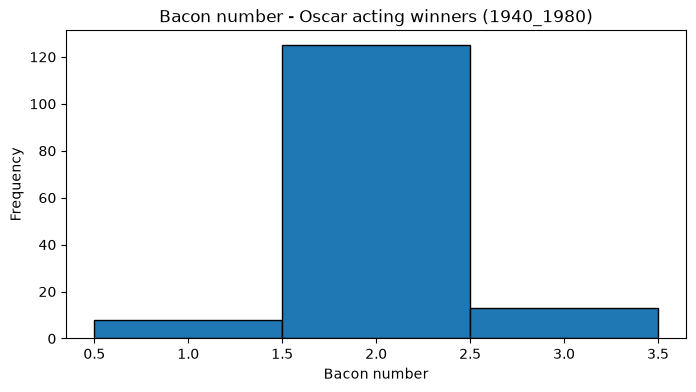

Parsed: 146 / 169 (skipped UNKNOWN/NONE)
Highest Bacon number: 3


In [86]:
bacon = pd.read_csv(Path("data/oscar_bacon_1940_1980.txt"), sep=";")
bacon["bacon"] = pd.to_numeric(bacon["bacon"], errors="coerce")
bacon_ok = bacon.dropna(subset=["bacon"]).astype({"bacon": int})

bins = range(int(bacon_ok["bacon"].min()), int(bacon_ok["bacon"].max()) + 2)

plt.figure(figsize=(8, 4))
plt.hist(bacon_ok["bacon"], bins=bins, edgecolor="black", align="left")
plt.title("Bacon number - Oscar acting winners (1940_1980)")
plt.xlabel("Bacon number")
plt.ylabel("Frequency")
plt.show()

print(f"Parsed: {len(bacon_ok)} / {len(bacon)} (skipped UNKNOWN/NONE)")
print(f"Highest Bacon number: {bacon_ok['bacon'].max()}")